#first generate dataset2_normal_then_control_meet_at_least_one_condition.csv

In [8]:
import numpy as np
import pandas as pd
import os

In [9]:
# initialize dataFrames
def initialize_dfs(names):
    return {name: pd.DataFrame() for name in names}
    
# function to read csv files into dataframes
def read_csv_files(names, df_dict, base_path):
    for name in names:
        file_path = os.path.join(base_path, name, "quantify_mirna/middle_results/blastn_hairpinrna.txt")
        df = pd.read_csv(file_path, sep='\t', usecols=[0,2],names=["qseqid", "stitle"],header=None)
        df['gene_name'] = df['stitle'].str.extract(r'(\S+)\s+stem-loop')
        df.drop(columns=['stitle'], inplace=True)
        df_dict[name] = df.groupby('gene_name')['qseqid'].nunique().reset_index()
        # Rename columns for clarity
        df_dict[name].columns = ['gene_name', 'unique_qseqid_count']

# Filter conditions: mirBase, linearfold, mirdeep2
# def filter_dataframes(names, df_source, df_with_match):
#     for name in names:
#         df_with_match[name] = filter_any_condition_met(df_source[name])
#         # df_all_zero[name] = filter_none_met(df_source[name])

# def filter_any_condition_met(df):
#     filtered_df = df[(df[['mirBase', 'linearfold', 'mirdeep2']].sum(axis=1) > 0)]
#     #filtered_df = filtered_df.loc[:, ['sequence']]
#     filtered_df = filtered_df.loc[:, ['sequence', 'qseqid_count']]
#     # print("filtered_df",filtered_df)
#     return filtered_df

# def filter_none_met(df):
#     filtered_df = df[(df[['mirBase', 'linearfold', 'mirdeep2']].sum(axis=1) == 0)]
#     filtered_df = filtered_df.loc[:, ['sequence']]
#     # filtered_df = filtered_df.loc[:, ['sequence', 'umi_count']]
#     # print("filtered_df_none",filtered_df)
#     return filtered_df

def merge_seqid_count(df, result_df, column_name):
    result_df = result_df.merge(df, on='gene_name', how='left').fillna(0)
    result_df = result_df.rename(columns={'unique_qseqid_count': column_name})
    return result_df

# function to generate form and save the result
def generate_and_save_result(names, df_dict, output_file):
    all_sequences = pd.concat([df_dict[name]['gene_name'] for name in names]).unique()
    result_df = pd.DataFrame({'gene_name': all_sequences})
    
    for name in names:
        df = df_dict[name]
        result_df = merge_seqid_count(df, result_df, f'{name}')
    print("result_df",result_df)
    result_df.to_csv(os.path.join(base_path, output_file), index=False)

In [10]:
# define the base path for output csv files
base_path = "../../../../2nd_6samples_output"

# names corresponding to the file names for normal and control
#first three is total group, second line is control group
total_names = [
    "SRR18078869", "SRR18078868", "SRR18078867",
    "SRR18078872", "SRR18078871", "SRR18078870"
]

# columns to read from the original CSV files
# read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']


#df_total = initialize_dfs(total_names)
df_total_with_match = initialize_dfs(total_names)


read_csv_files(total_names, df_total_with_match, base_path)


# filter_dataframes(total_names, df_total, df_total_with_match)
for name in total_names:
    num_rows = len(df_total_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")

print(df_total_with_match)


generate_and_save_result(total_names, df_total_with_match, "dataset2_DSS_then_control_mirna_count_gene_name.csv")


DataFrame SRR18078869 has 11756 lines.
DataFrame SRR18078868 has 12459 lines.
DataFrame SRR18078867 has 13155 lines.
DataFrame SRR18078872 has 14894 lines.
DataFrame SRR18078871 has 15295 lines.
DataFrame SRR18078870 has 13945 lines.
{'SRR18078869':         gene_name  unique_qseqid_count
0          bantam                39071
1        bantam-a                    1
2        bantam-b                    9
3      bantam-c-1                    2
4      bantam-c-2                    2
...           ...                  ...
11751     miR9780                  345
11752     miR9783                  114
11753    miR9863a                   15
11754    miR9863b                   15
11755     miR9897                  104

[11756 rows x 2 columns], 'SRR18078868':         gene_name  unique_qseqid_count
0          bantam                14318
1        bantam-a                    1
2        bantam-b                    9
3      bantam-c-1                   13
4      bantam-c-2                   13
...   

In [11]:
#then use above two files to generate PCA figure.

In [2]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import os
import pandas as pd
import glob

In [3]:
base_path = "../../../../2nd_6samples_output"

In [4]:

total_df = pd.read_csv(os.path.join(base_path, "dataset2_DSS_then_control_mirna_count_gene_name.csv"), sep=",")
# control_df = pd.read_csv(os.path.join(base_path, "dataset2_control_meet_at_least_one_condition.csv"), sep=",")

In [5]:
total = total_df.drop('gene_name', axis=1)
# print(total.head())
### totalize
total_totalized = total.div(total.sum())
#print(total_totalized.head())
total_totalized = total_totalized.mul(10**6).astype(int)

matrix_transpose_total = total_totalized.T.reset_index()
y_total = matrix_transpose_total['index'].to_list()
print(matrix_transpose_total)
# print(y_total)

         index      0  1  2  3  4  5     6  7  8  ...  17735  17736  17737  \
0  SRR18078869   8331  0  1  0  0  0  9149  0  0  ...      0      0      0   
1  SRR18078868   3609  0  2  3  3  0   496  0  0  ...      0      0      0   
2  SRR18078867  13352  0  1  0  0  0  4630  0  0  ...      0      0      0   
3  SRR18078872   1263  0  1  0  0  0  1497  0  0  ...      0      0      0   
4  SRR18078871   1351  0  0  7  7  0   382  0  0  ...      0      0      0   
5  SRR18078870   4271  0  0  0  0  0   745  0  0  ...      0      0      0   

   17738  17739  17740  17741  17742  17743  17744  
0      0      0      0      0      0      0      0  
1      0      0      0      0      0      0      0  
2      0      0      0      0      0      0      0  
3      0      0      0      0      0      0      0  
4      0      0      0      0      0      0      0  
5      1      0      0      0      0      0      1  

[6 rows x 17746 columns]


aaa
[[ 8331     0     1 ...     0     0     0]
 [ 3609     0     2 ...     0     0     0]
 [13352     0     1 ...     0     0     0]
 [ 1263     0     1 ...     0     0     0]
 [ 1351     0     0 ...     0     0     0]
 [ 4271     0     0 ...     0     0     1]]
[[ 0.69381932  0.          0.24253563 ...  0.          0.
  -0.4472136 ]
 [-0.40996466  0.          1.69774938 ...  0.          0.
  -0.4472136 ]
 [ 1.86749559  0.          0.24253563 ...  0.          0.
  -0.4472136 ]
 [-0.95835035  0.          0.24253563 ...  0.          0.
  -0.4472136 ]
 [-0.93778004  0.         -1.21267813 ...  0.          0.
  -0.4472136 ]
 [-0.25521985  0.         -1.21267813 ...  0.          0.
   2.23606798]]
Mean after standardization: [ 9.25185854e-17  0.00000000e+00 -7.40148683e-17 ...  0.00000000e+00
  0.00000000e+00  0.00000000e+00]
Std dev after standardization: [1. 0. 1. ... 0. 0. 1.]
Standard Deviations: [1. 0. 1. ... 0. 0. 1.]
Features with zero variance: [    1     5     7 ... 17741 17742 177

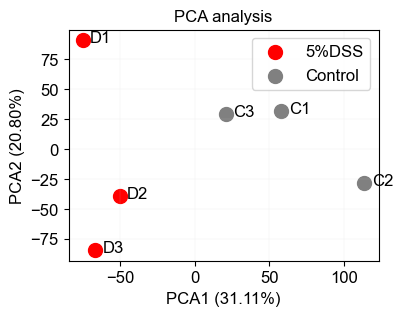

In [13]:
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm


fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=12)
print("aaa")

X = matrix_transpose_total.drop(columns='index').to_numpy()
print(X)


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled)
print("Mean after standardization:", X_scaled.mean(axis=0))
print("Std dev after standardization:", X_scaled.std(axis=0))
stds = X_scaled.std(axis=0)
print("Standard Deviations:", stds)
zero_var_features = np.where(stds == 0)[0]
print("Features with zero variance:", zero_var_features)
data_reduced = np.delete(X_scaled, zero_var_features, axis=1)
print("Std dev after filter 0 standardization:", data_reduced.std(axis=0))


pca = PCA(n_components=2)
X_pca = pca.fit_transform(data_reduced)


pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
print(pca_df)


pca_df['Sample'] = ['D1', 'D2', 'D3','C1','C2','C3']
# pca_df['Sample'] = y_total
print(y_total)
pca_df['Group'] = ['5%DSS','5%DSS','5%DSS','Control','Control','Control']


plt.figure(figsize=(4, 3))
colors = {'5%DSS': 'red', 'Control': 'gray'}

for group in pca_df['Group'].unique():
    subset = pca_df[pca_df['Group'] == group]
    plt.scatter(subset['PC1'], subset['PC2'], label=group, color=colors[group], s=100)

for i, row in pca_df.iterrows():
    plt.text(row['PC1']+5, row['PC2']-2, row['Sample'],fontproperties=arial_font) 


plt.title("PCA analysis",fontproperties=arial_font)
plt.xlabel(f'PCA1 ({pca.explained_variance_ratio_[0]*100:.2f}%)',fontproperties=arial_font)
plt.ylabel(f'PCA2 ({pca.explained_variance_ratio_[1]*100:.2f}%)',fontproperties=arial_font)

plt.legend(prop=arial_font)

plt.xticks(fontproperties=arial_font)
plt.yticks(fontproperties=arial_font)

plt.grid(True, color="lightgray", linewidth=0.1)

# plt.show()
plt.savefig("supp_figureX_A.pdf", format="pdf", bbox_inches="tight")
